In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, cheby1, bilinear, lfilter

# ---------- Parameters ----------
fs = 20000                          # sampling frequency (Hz)
t = np.arange(0, 0.05, 1/fs)        # 50 ms of time -> 1000 samples
freqs = [1000, 2000, 3000, 4000]    # sine frequencies (Hz)
n_show = 100                        # samples shown in time plots (5 ms)

# ---------- Helper functions ----------
def spectrum(x):
    # single-sided amplitude spectrum
    X = np.abs(np.fft.rfft(x)) * 2 / len(x)
    f = np.fft.rfftfreq(len(x), 1/fs)
    return f, X

def plot_time_freq(x, title):
    f, X = spectrum(x)
    plt.figure(figsize=(10, 6))

    plt.subplot(2, 1, 1)
    plt.stem(t[:n_show]*1000, x[:n_show])
    plt.title(title + " - Time Domain")
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
    plt.grid(True)

    plt.subplot(2, 1, 2)
    plt.plot(f/1000, X)
    plt.title(title + " - Frequency Domain")
    plt.xlabel("Frequency (kHz)")
    plt.ylabel("Magnitude")
    plt.grid(True)

    plt.tight_layout()
    plt.show()

def bilinear_design(kind, order, fc, fs, ripple=1):
    # pre-warp the cutoff, design analog low-pass, then apply bilinear transform
    wc = 2 * fs * np.tan(np.pi * fc / fs)
    if kind == 'butter':
        b, a = butter(order, wc, btype='low', analog=True)
    else:
        b, a = cheby1(order, ripple, wc, btype='low', analog=True)
    return bilinear(b, a, fs)

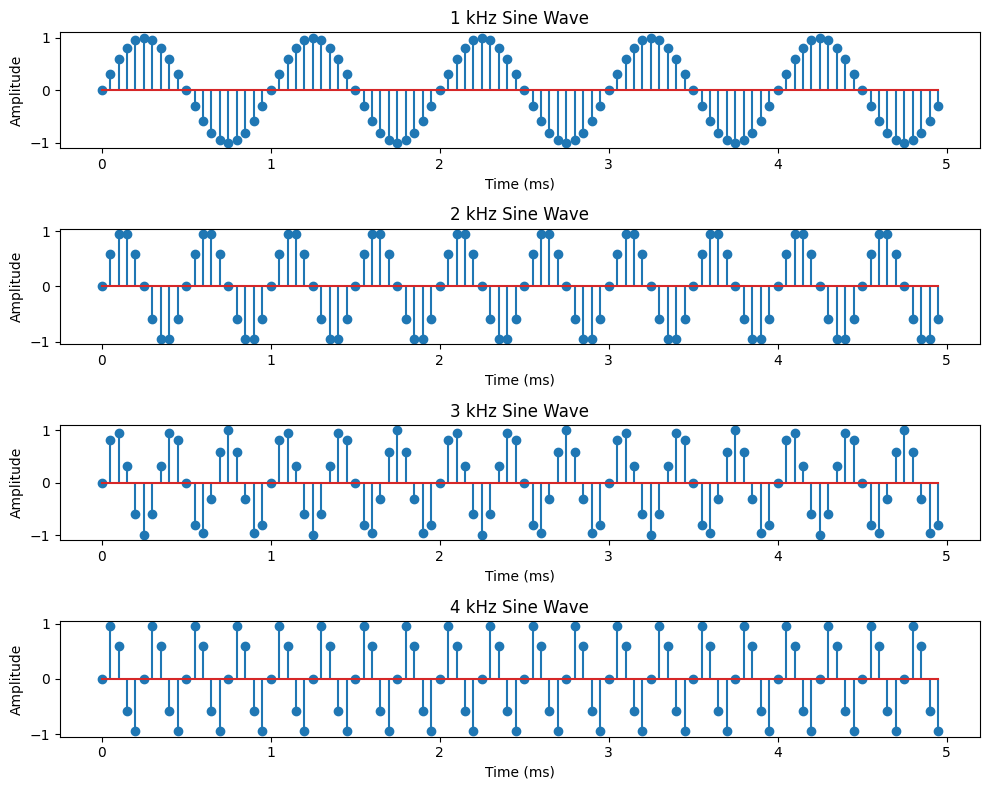

In [2]:
# ---------- 1. Individual sine waves ----------
sines = [np.sin(2*np.pi*f*t) for f in freqs]

plt.figure(figsize=(10, 8))
for i, (f, s) in enumerate(zip(freqs, sines)):
    plt.subplot(4, 1, i+1)
    plt.stem(t[:n_show]*1000, s[:n_show])
    plt.title(f"{f//1000} kHz Sine Wave")
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

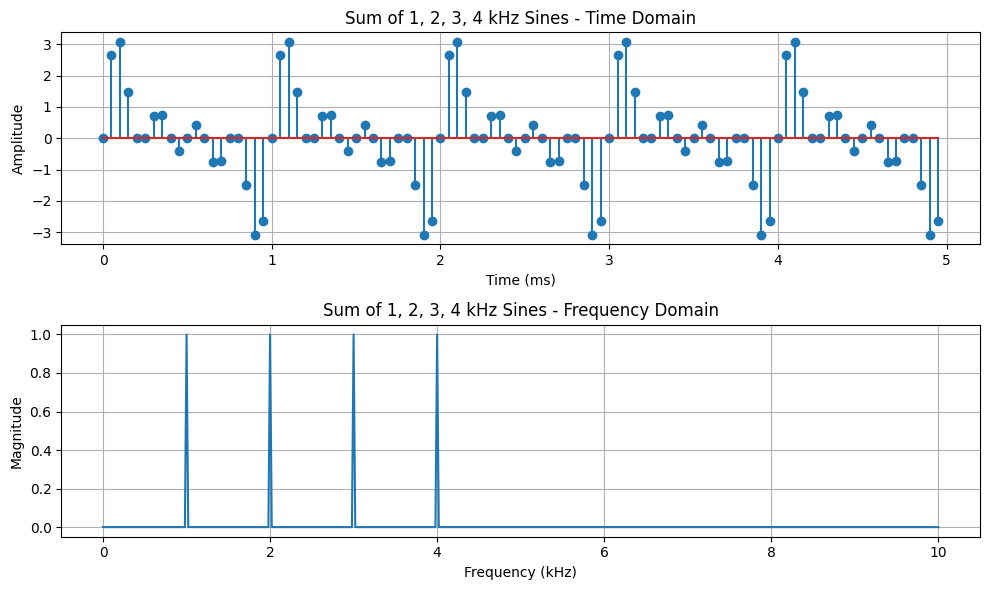

In [3]:
# ---------- 2. Sum of all four signals ----------
x = sum(sines)
plot_time_freq(x, "Sum of 1, 2, 3, 4 kHz Sines")

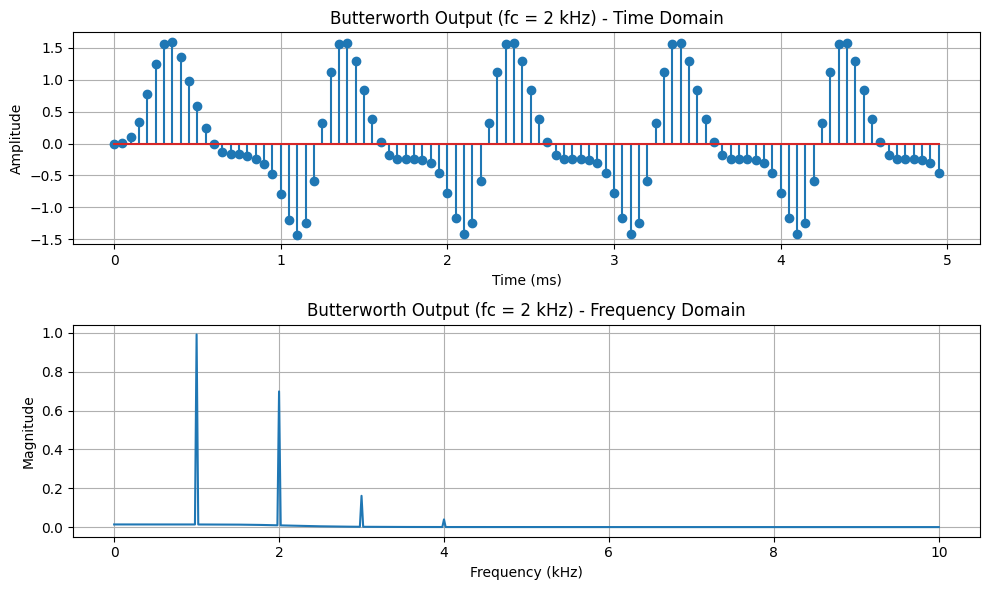

In [4]:
# ---------- 3. Butterworth low-pass filter (fc = 2 kHz) ----------
b_bw, a_bw = bilinear_design('butter', 4, 2000, fs)
y_bw = lfilter(b_bw, a_bw, x)
plot_time_freq(y_bw, "Butterworth Output (fc = 2 kHz)")

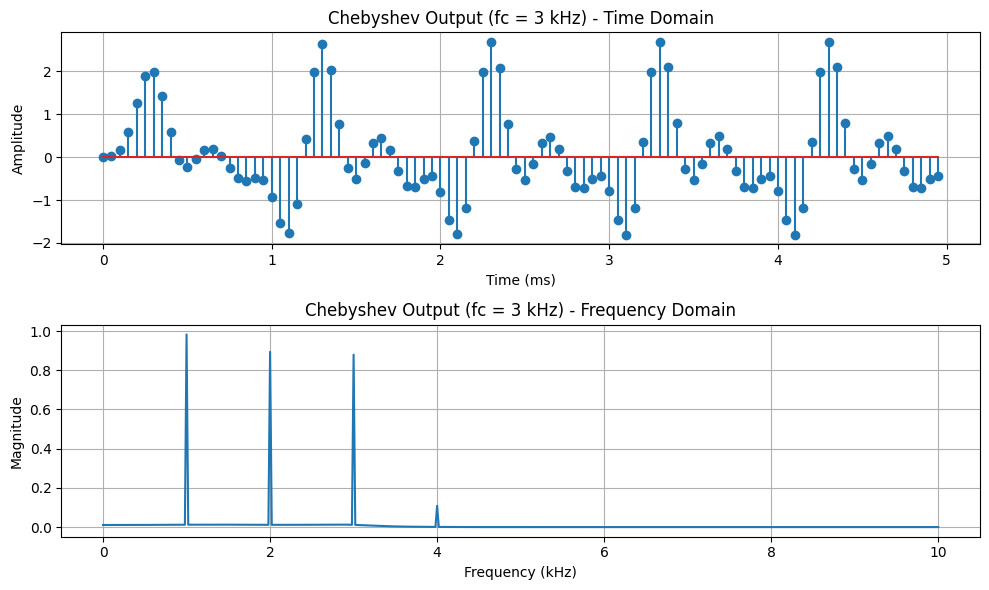

In [5]:
# ---------- 4. Chebyshev Type-I low-pass filter (fc = 3 kHz) ----------
b_ch, a_ch = bilinear_design('cheby', 4, 3000, fs, ripple=1)
y_ch = lfilter(b_ch, a_ch, x)
plot_time_freq(y_ch, "Chebyshev Output (fc = 3 kHz)")